# Week 5: Linear and Logistic Regression
**Assignments: 51, 52**

Linear regression and logistic regression with scikit-learn. The datasets are typed in or built into scikit-learn, so nothing needs to be downloaded.

## Required Libraries and Modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
)

## Assignment 51: Linear Regression with scikit-learn (Week 5, Day 1)
Predict a student's exam **score** from the number of **hours** they studied.
Linear regression fits a straight line: **score = intercept + slope × hours**.

           Hours     Scores
count  25.000000  25.000000
mean    5.012000  51.480000
std     2.525094  25.286887
min     1.100000  17.000000
25%     2.700000  30.000000
50%     4.800000  47.000000
75%     7.400000  75.000000
max     9.200000  95.000000


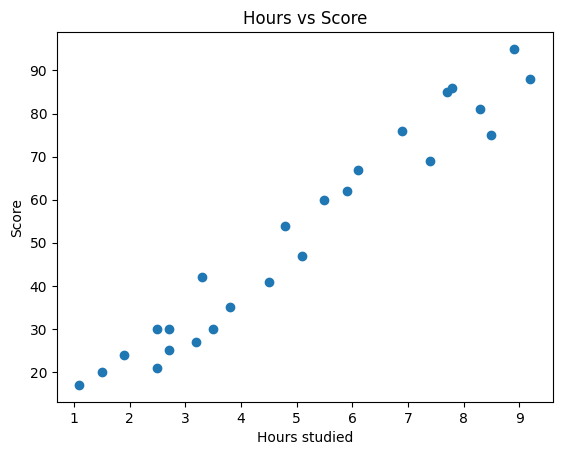

In [2]:
students = pd.DataFrame({
    "Hours": [2.5, 5.1, 3.2, 8.5, 3.5, 1.5, 9.2, 5.5, 8.3, 2.7, 7.7, 5.9, 4.5,
              3.3, 1.1, 8.9, 2.5, 1.9, 6.1, 7.4, 2.7, 4.8, 3.8, 6.9, 7.8],
    "Scores": [21, 47, 27, 75, 30, 20, 88, 60, 81, 25, 85, 62, 41,
               42, 17, 95, 30, 24, 67, 69, 30, 54, 35, 76, 86],
})

print(students.describe())

students.plot(x="Hours", y="Scores", style="o", legend=False)
plt.title("Hours vs Score")
plt.xlabel("Hours studied")
plt.ylabel("Score")
plt.show()

In [3]:
X = students[["Hours"]]
y = students["Scores"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressor = LinearRegression()
regressor.fit(X_train, y_train)

print("Intercept:", round(regressor.intercept_, 2))
print("Slope    :", round(regressor.coef_[0], 2))

Intercept: 2.83
Slope    : 9.68


In [4]:
y_pred = regressor.predict(X_test)

comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred.round(1)})
print(comparison)

print("\nMean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error :", round(mean_squared_error(y_test, y_pred), 2))
print("Root MSE           :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 score           :", round(r2_score(y_test, y_pred), 3))

hours = 9.25
print(f"\nPredicted score for {hours} hours:", round(regressor.predict(pd.DataFrame({"Hours": [hours]}))[0], 1))

    Actual  Predicted
8       81       83.2
16      30       27.0
0       21       27.0
23      76       69.6
11      62       60.0

Mean Absolute Error: 3.92
Mean Squared Error : 18.94
Root MSE           : 4.35
R2 score           : 0.968

Predicted score for 9.25 hours: 92.4


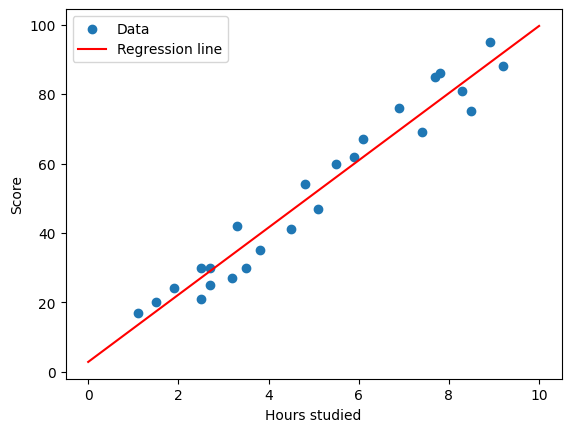

In [5]:
line_x = np.linspace(0, 10, 100).reshape(-1, 1)
plt.scatter(X, y, label="Data")
plt.plot(line_x, regressor.predict(pd.DataFrame(line_x, columns=["Hours"])), color="red", label="Regression line")
plt.xlabel("Hours studied")
plt.ylabel("Score")
plt.legend()
plt.show()

## Assignment 52: Logistic Regression (Week 5, Day 3)
Classify handwritten digits (0–9) with logistic regression. The **digits** dataset is a small,
built-in version of MNIST with 8×8 pixel images.

Image data shape: (1797, 64)
Label shape     : (1797,)


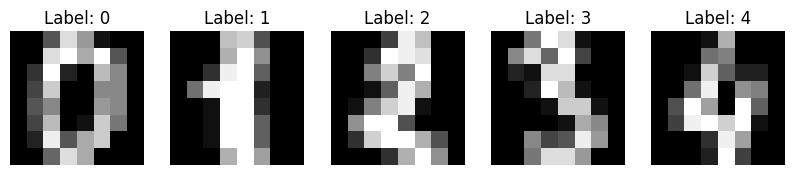

In [6]:
digits = load_digits()
print("Image data shape:", digits.data.shape)
print("Label shape     :", digits.target.shape)

plt.figure(figsize=(10, 2))
for index in range(5):
    plt.subplot(1, 5, index + 1)
    plt.imshow(digits.images[index], cmap="gray")
    plt.title(f"Label: {digits.target[index]}")
    plt.axis("off")
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=0
)

log_reg = LogisticRegression(max_iter=5000)
log_reg.fit(X_train, y_train)

predictions = log_reg.predict(X_test)
print("Prediction for first test image:", predictions[0], "| actual:", y_test[0])
print("Accuracy:", round(log_reg.score(X_test, y_test), 3))

Prediction for first test image: 2 | actual: 2
Accuracy: 0.953


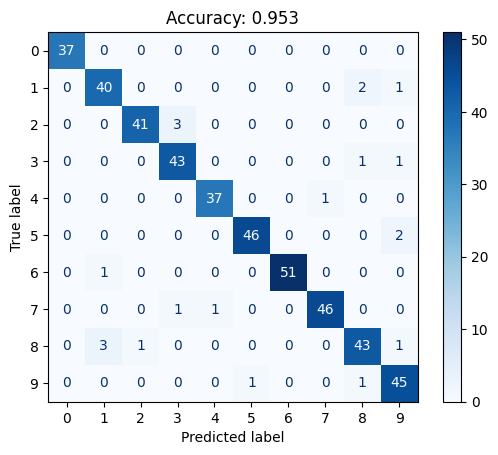

In [8]:
cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
plt.show()

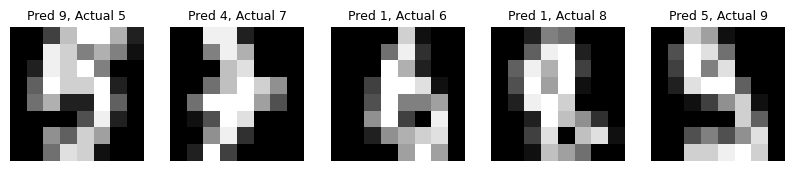

In [9]:
# show some images the model got wrong
wrong = np.where(predictions != y_test)[0]

plt.figure(figsize=(10, 2))
for plot_index, wrong_index in enumerate(wrong[:5]):
    plt.subplot(1, 5, plot_index + 1)
    plt.imshow(X_test[wrong_index].reshape(8, 8), cmap="gray")
    plt.title(f"Pred {predictions[wrong_index]}, Actual {y_test[wrong_index]}", fontsize=9)
    plt.axis("off")
plt.show()